<a href="https://colab.research.google.com/github/Mufliha-Hafsyah/Machine-Learning/blob/main/Week06/Tugas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **PRAKTIKUM PEMBELAJARAN MESIN**

**Nama**  : Mufliha Hafsyah Shahieza <br>
**NIM**   : 244107020147 <br>
**Kelas** : TI-3G

---

# **JS06 - ANN (Approximate Nearest Neighbors)**<hr>
# **Tugas**
Jalankan code berikut pada Google Colab dan PyDroid3 (Android Python) Application di Smartphone Android. Bandingkan hasilnya dan tuliskan analisa anda, tuliskan juga spesifikasi smartphone yang anda gunakan :).

In [ ]:
import numpy as np
import time
from sklearn.neighbors import NearestNeighbors
from annoy import AnnoyIndex
import hnswlib
import faiss
from sklearn.preprocessing import StandardScaler

# -------------------------------
# Contoh dataset kecil untuk testing
# -------------------------------
np.random.seed(42)
n_samples = 10000   # jumlah database vector
d = 128             # dimensi
X = np.random.random((n_samples, d)).astype('float32')

# Standarisasi fitur
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

k = 10  # jumlah nearest neighbors

# -------------------------------
# Exact NN (brute-force)
# -------------------------------
start = time.time()
nn = NearestNeighbors(n_neighbors=k, algorithm='brute', metric='euclidean')
nn.fit(X_scaled)
dist_exact, idx_exact = nn.kneighbors(X_scaled)
time_exact = time.time() - start
print(f"Exact NN done in {time_exact:.3f} s")

# -------------------------------
# Annoy
# -------------------------------
start = time.time()
f = X_scaled.shape[1]
index_annoy = AnnoyIndex(f, 'euclidean')
for i, v in enumerate(X_scaled):
    index_annoy.add_item(i, v)
index_annoy.build(10)
idx_annoy = [index_annoy.get_nns_by_vector(v, k) for v in X_scaled]
time_annoy = time.time() - start
print(f"Annoy done in {time_annoy:.3f} s")

# -------------------------------
# HNSW
# -------------------------------
start = time.time()
p_hnsw = hnswlib.Index(space='l2', dim=d)
p_hnsw.init_index(max_elements=n_samples, ef_construction=200, M=16)
p_hnsw.add_items(X_scaled)
p_hnsw.set_ef(200)
idx_hnsw, _ = p_hnsw.knn_query(X_scaled, k=k)
time_hnsw = time.time() - start
print(f"HNSW done in {time_hnsw:.3f} s")

# -------------------------------
# FAISS IVF
# -------------------------------
start = time.time()
quantizer = faiss.IndexFlatL2(d)
index_faiss = faiss.IndexIVFFlat(quantizer, d, 100, faiss.METRIC_L2)
index_faiss.train(X_scaled)
index_faiss.add(X_scaled)
index_faiss.nprobe = 10
_, idx_faiss = index_faiss.search(X_scaled, k)
time_faiss = time.time() - start
print(f"FAISS IVF done in {time_faiss:.3f} s")

# -------------------------------
# Tampilkan ringkasan waktu
# -------------------------------
print("\n=== Ringkasan Waktu (detik) ===")
print(f"Exact NN : {time_exact:.3f}")
print(f"Annoy    : {time_annoy:.3f}")
print(f"HNSW     : {time_hnsw:.3f}")
print(f"FAISS    : {time_faiss:.3f}")


Exact NN done in 1.702 s
Annoy done in 0.597 s
HNSW done in 5.230 s
FAISS IVF done in 0.374 s

=== Ringkasan Waktu (detik) ===
Exact NN : 1.702
Annoy    : 0.597
HNSW     : 5.230
FAISS    : 0.374


In [ ]:
def recall(I_pred, I_gt, k=10):
    return sum(len(set(map(int, p[:k])) & set(map(int, g[:k]))) for p, g in zip(I_pred, I_gt)) / (len(I_gt) * k)

print("Recall Annoy:", round(recall(idx_annoy, idx_exact), 3))
print("Recall HNSW :", round(recall(idx_hnsw, idx_exact), 3))
print("Recall FAISS:", round(recall(idx_faiss, idx_exact), 3))

Recall Annoy: 0.168
Recall HNSW : 0.981
Recall FAISS: 0.418


In [ ]:
!lscpu | grep -E "Model name|^CPU\(s\)"
!free -h | head -2

CPU(s):                                  2
Model name:                              Intel(R) Xeon(R) CPU @ 2.20GHz
               total        used        free      shared  buff/cache   available
Mem:            12Gi       1.7Gi       8.7Gi       3.4Mi       2.6Gi        10Gi


### **Perbandingan Google Colab vs Pydroid 3 (10.000 data, 128D, k=10)**

| Metode | Waktu Colab (detik) | Waktu Pydroid 3 (detik) | Pydroid / Colab | Recall Colab | Recall Pydroid 3 |
|---|---|---|---|---|---|
| Exact NN | 1.702 | 2.082 | sekitar 1,2x | 1.0 (acuan) | 1.0 (acuan) |
| Annoy (10 tree) | 0.597 | 4.719 | sekitar 7,9x | 0.168 | 0.168 |
| HNSW (ef=200) | 5.230 | 12.855 | sekitar 2,5x | 0.981 | 0.980 |
| FAISS IVF | 0.374 | tidak dapat dipasang | - | 0.418 | tidak tersedia |

**Spesifikasi:**
- Google Colab: Intel Xeon CPU @ 2.20 GHz, 2 vCPU, RAM 12 GB
- Smartphone: Samsung Galaxy A12 (SM-A125F/DS), RAM 4 GB, chipset MediaTek Helio P35 (MT6765), Android 12, arsitektur aarch64 (8 core), Python 3.13.13 (Pydroid 3)

**Analisis:**

1. **Urutan kecepatan berbeda antar perangkat.** Di Colab, urutan tercepat adalah FAISS IVF (0.374 s), Annoy (0.597 s), Exact NN (1.702 s), lalu HNSW (5.230 s). Di Pydroid 3, urutannya Exact NN (2.082 s), Annoy (4.719 s), lalu HNSW (12.855 s). Annoy lebih cepat dari Exact NN di Colab, tetapi lebih lambat dari Exact NN di HP.
2. **Dampak terbesar pada Annoy.** Waktu Annoy di HP sekitar 7,9 kali lebih lama dari Colab, sedangkan Exact NN hanya sekitar 1,2 kali dan HNSW sekitar 2,5 kali. Kemungkinan penyebabnya, Exact NN memakai perkalian matriks yang sangat teroptimasi (NumPy/scikit-learn), sedangkan Annoy dijalankan lewat loop Python untuk tiap data (puluhan ribu panggilan `add_item` dan `get_nns_by_vector`), dan pustakanya bisa saja dikompilasi tanpa optimasi pada Android. Ini dugaan, bukan hasil pengukuran langsung.
3. **HNSW paling lambat di kedua perangkat** karena waktunya mencakup pembangunan graf (`ef_construction=200`), tetapi menghasilkan recall tertinggi (0.980 di Pydroid). Annoy dengan 10 tree hanya mencapai recall 0.168 pada data acak 128 dimensi.
4. **Data 10.000 terlalu kecil untuk menunjukkan keunggulan ANN.** Exact NN tetap kompetitif, dan di HP bahkan tercepat, karena biaya membangun indeks lebih besar daripada penghematan pencarian. Keunggulan ANN muncul pada data yang jauh lebih besar.
5. **FAISS tidak dapat dipasang di Pydroid 3** (Android, aarch64, Python 3.13) karena tidak tersedia paket biner siap pakai dan kompilasi dari sumber gagal (`swig` tidak ditemukan). Ini menunjukkan keterbatasan ekosistem library ANN di perangkat mobile.
6. **Akurasi tidak bergantung perangkat.** Recall Annoy sama persis di kedua perangkat (0.168), dan recall HNSW hampir sama (0.981 di Colab, 0.980 di Pydroid). Selisih kecil pada HNSW kemungkinan berasal dari proses penyisipan data ke graf yang berjalan paralel (urutannya bisa sedikit berbeda tiap run). Artinya perbedaan antar perangkat hanya terletak pada waktu eksekusi (Colab: Xeon 2 vCPU; HP: Helio P35 8 core ARM).
7. **Perbandingan akurasi antar metode (Colab).** HNSW paling akurat (0.981), disusul FAISS IVF (0.418), dan Annoy paling rendah (0.168). FAISS IVF adalah yang tercepat di Colab (0.374 detik) tetapi dengan recall menengah, sedangkan HNSW membayar akurasi tingginya dengan waktu build terlama (5.230 detik). Rendahnya recall Annoy dan FAISS sebagian disebabkan datanya acak berdimensi tinggi (128D), yang paling sulit bagi pencarian aproksimasi.

Gambar Output Pydroid 3 pada Samsung Galaxy A12

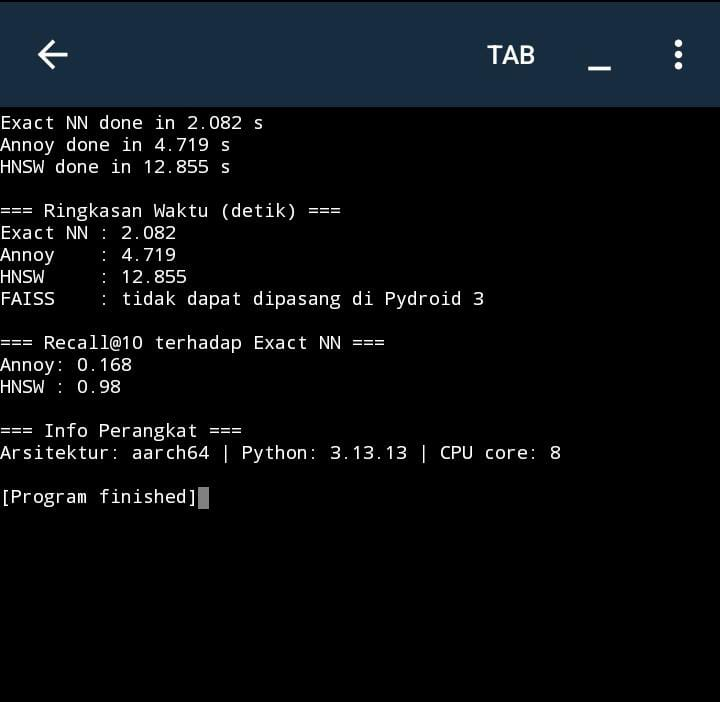